# ⚡ Lesson 01 · The Artificial Neuron & the Perceptron

*“Every giant neural network is, at heart, a crowd of very simple decision-makers.”*

| ⏱ Time | 🎚 Level | 🗓 Suggested day | 📚 You should know |
|:--|:--|:--|:--|
| ~75 min | 🟢 Beginner | Day 1–2 | Lesson 00, NumPy |

## 🎯 Learning objectives
By the end of this lesson you will be able to:

- Describe an artificial neuron as *weighted sum + bias → activation*
- Explain what **weights** and a **bias** mean, geometrically and in everyday terms
- Hand-build neurons that compute AND, OR and NAND
- Implement the **perceptron learning rule** from scratch and watch the decision boundary move
- Explain *why a single perceptron cannot learn XOR*: the problem that motivates deep networks

## 🗺 Roadmap
1. A decision you already make like a neuron
2. The neuron, formally
3. What weights & bias do geometrically
4. Logic gates by hand
5. The perceptron learning rule
6. Watching it learn
7. The XOR wall
8. Problems

## ⚙️ Setup
Run this cell first. It loads our libraries and the course helper module (`utils/dlcourse.py`).

In [1]:
import sys; sys.path.append("..")          # so we can import the course helper library
import numpy as np
import matplotlib.pyplot as plt
from utils import dlcourse as dl

dl.set_seed(42)                          # reproducible randomness
%matplotlib inline

---
## 🌱 1. A decision you already make like a neuron

You are a smallholder farmer in Kiambu. *Should you plant maize this week?* You weigh a few signals:

| Signal | Value `x` | How much you care (weight `w`) |
|:--|:-:|:-:|
| Rain forecast is good (1 = yes, 0 = no) | `x₁` | **+3**: rain is crucial |
| Soil is moist enough (1/0) | `x₂` | **+2** |
| Seed price is high (1/0) | `x₃` | **−2**: expensive seed discourages you |

And you have a baseline attitude: you're a cautious person, so unless the evidence is strong you *don't* plant. Call that
**bias `b = −3`**. You plant if the total score is positive:

$$z = w_1x_1 + w_2x_2 + w_3x_3 + b \qquad\qquad \text{plant if } z > 0$$

**That is an artificial neuron.** Nothing more. Inputs are multiplied by importance-weights, summed, shifted by a bias,
and passed through a rule (here: "is it positive?") that produces the output.

In [2]:
def farmer_neuron(rain_good, soil_moist, seed_expensive):
    x = np.array([rain_good, soil_moist, seed_expensive])
    w = np.array([3.0, 2.0, -2.0])      # how much each signal matters
    b = -3.0                            # baseline caution
    z = np.dot(w, x) + b                # weighted sum + bias
    return z, int(z > 0)                # decision: 1 = plant, 0 = wait

for scenario in [(1, 1, 0), (1, 0, 0), (1, 1, 1), (0, 1, 0)]:
    z, plant = farmer_neuron(*scenario)
    print(f"rain={scenario[0]} soil={scenario[1]} seedPriceHigh={scenario[2]}  →  z={z:+.0f}  →  {'PLANT 🌽' if plant else 'wait'}")

rain=1 soil=1 seedPriceHigh=0  →  z=+2  →  PLANT 🌽
rain=1 soil=0 seedPriceHigh=0  →  z=+0  →  wait
rain=1 soil=1 seedPriceHigh=1  →  z=+0  →  wait
rain=0 soil=1 seedPriceHigh=0  →  z=-1  →  wait


🤔 **Pause and think.** Scenario (1, 0, 0): good rain, dry soil, cheap seed. The farmer waits. What would you change so they *would* plant?

<details><summary>Click to reveal the answer</summary>

Many options! Raise the weight on rain (`w₁ = 4` gives `z = +1`), or lower the caution (`b = −2`). **That's all learning will ever be:** finding weights and a bias that produce the decisions we want.

</details>

---
## ⚙️ 2. The artificial neuron, formally

For inputs $\mathbf{x} = (x_1,\dots,x_n)$ a neuron has **weights** $\mathbf{w}$ and a **bias** $b$:

$$z = \mathbf{w}\cdot\mathbf{x} + b = \sum_{i=1}^{n} w_i x_i + b \qquad\qquad a = f(z)$$

* $z$: the *pre-activation* (the "score"),
* $f$: the **activation function** (step, sigmoid, ReLU, … Lesson 02),
* $a$: the neuron's **output**.

```
   x₁ ──w₁──╲
   x₂ ──w₂───▶ [ Σ wᵢxᵢ + b ] ──▶ f(·) ──▶ a
   x₃ ──w₃──╱          ▲
                       b (bias)
```

> 📜 **A little history.** In 1943 McCulloch & Pitts proposed a mathematical neuron loosely inspired by brain cells.
> In 1958 Frank Rosenblatt built the **Perceptron**: a neuron that could *learn its own weights*, and the New York Times
> reported it as the embryo of a computer that would "walk, talk, see, write, reproduce itself". (We're still working on that.)
> Biological neurons are **far** more complicated; "neural" is an inspiration, not a blueprint.

### The two knobs, in plain language

* **Weight $w_i$ = importance and direction of input $i$.** Large positive → "this input pushes toward YES".
  Negative → "this pushes toward NO". Near zero → "ignore it".
* **Bias $b$ = how easily the neuron fires on its own.** A large negative bias means "I need strong evidence";
  a positive bias means "I'm trigger-happy".

### 🧮 Worked example: A perceptron by hand

**Problem.** A neuron has weights $w=(2,-1)$, bias $b=-1$, and uses the step activation (output 1 if $z>0$, else 0). Compute its output for $x=(1,1)$ and $x=(0,1)$.

**Step 1.** Compute $z$ for the first input: $z = 2\cdot1 + (-1)\cdot1 + (-1) = 0$.

**Step 2.** Step rule: is $z>0$? No ($z=0$ is *not* > 0) → output **0**.

**Step 3.** Second input: $z = 2\cdot0 + (-1)\cdot1 - 1 = -2$ → output **0**.

**Step 4.** Try $x=(1,0)$: $z = 2 - 0 - 1 = 1 > 0$ → output **1**. This neuron fires only when $x_1$ is on and $x_2$ is off.

In [3]:
def neuron(x, w, b):
    return int(np.dot(w, x) + b > 0)

w, b = np.array([2., -1.]), -1.
for x in [(1, 1), (0, 1), (1, 0), (0, 0)]:
    print(x, "→", neuron(np.array(x), w, b))

(1, 1) → 0
(0, 1) → 0
(1, 0) → 1
(0, 0) → 0


---
## 📐 3. What weights and bias do, geometrically

With two inputs, the equation $w_1x_1 + w_2x_2 + b = 0$ is a **straight line** in the $(x_1,x_2)$ plane.
Points on one side give $z>0$ (output 1); the other side gives $z<0$ (output 0).

* The **weight vector $\mathbf{w}$ is perpendicular to the line** and points toward the "1" side.
* The **bias slides the line** away from or toward the origin.

So a neuron is a **linear classifier**: it draws one straight cut through space. Let's see how changing $w$ and $b$ moves it.

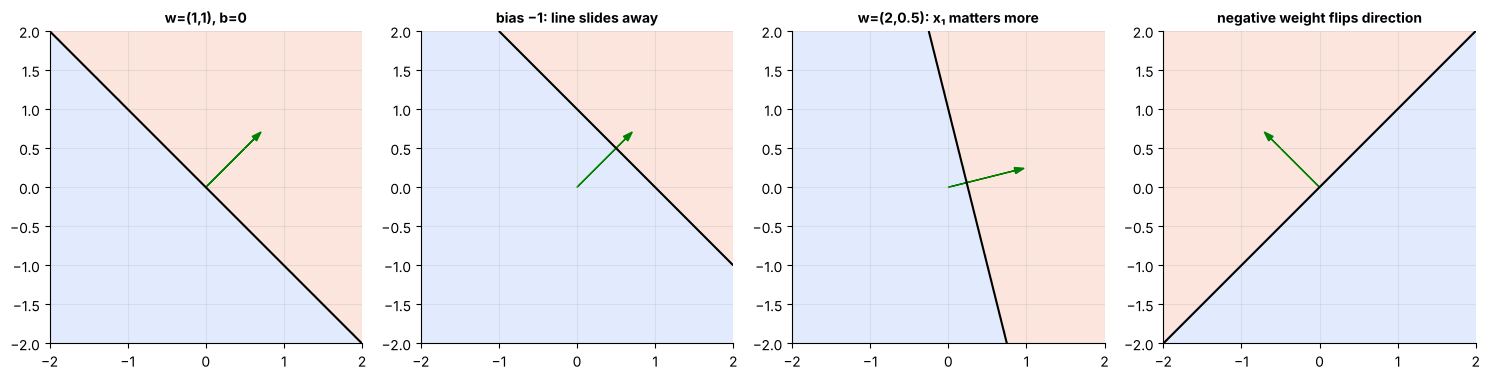

In [4]:
def boundary_plot(ax, w, b, title):
    xs = np.linspace(-2, 2, 200)
    ax.set_xlim(-2, 2); ax.set_ylim(-2, 2)
    # shade z>0 region
    xx, yy = np.meshgrid(np.linspace(-2, 2, 100), np.linspace(-2, 2, 100))
    zz = w[0] * xx + w[1] * yy + b
    ax.contourf(xx, yy, zz > 0, alpha=.25, cmap="coolwarm", levels=[-.5, .5, 1.5])
    ax.contour(xx, yy, zz, levels=[0], colors="k")
    ax.arrow(0, 0, w[0] / np.linalg.norm(w), w[1] / np.linalg.norm(w), head_width=.08, color="green", length_includes_head=True)
    ax.set_title(title, fontsize=10); ax.set_aspect("equal")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
boundary_plot(axes[0], np.array([1., 1.]), 0.0, "w=(1,1), b=0")
boundary_plot(axes[1], np.array([1., 1.]), -1.0, "bias −1: line slides away")
boundary_plot(axes[2], np.array([2., 0.5]), -0.5, "w=(2,0.5): x₁ matters more")
boundary_plot(axes[3], np.array([-1., 1.]), 0.0, "negative weight flips direction")
plt.tight_layout(); plt.show()

> 💡 **Big idea**: A neuron answers *one* question: **"Which side of my line is this point on?"** Training = moving the line. The green arrow is $\mathbf{w}$: it always points to the side that outputs 1.

---
## 🔌 4. Logic gates by hand

Let's prove neurons are useful by *designing* weights to compute logic. Recall AND outputs 1 only if **both** inputs are 1.
To make a neuron that does this, we need $x_1+x_2$ to exceed a threshold only when both are 1:

* Choose $w=(1,1)$. Then $z = x_1+x_2+b$ ranges over $\{b, 1+b, 2+b\}$.
* We want $z>0$ only for $x=(1,1)$, so $2+b>0$ but $1+b\le 0$ → **$b=-1.5$** works.

For **OR** we want $z>0$ if *at least one* is on: $b=-0.5$.

In [5]:
inputs = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])

def gate(w, b):
    return (inputs @ np.array(w) + b > 0).astype(int)     # all four inputs at once!

print("x1 x2 | AND OR")
and_out, or_out = gate([1, 1], -1.5), gate([1, 1], -0.5)
for (x1, x2), a, o in zip(inputs, and_out, or_out):
    print(f" {x1}  {x2}  |  {a}   {o}")

x1 x2 | AND OR
 0  0  |  0   0
 0  1  |  0   1
 1  0  |  0   1
 1  1  |  1   1


🤔 **Pause and think.** Can you find weights and a bias for **NOT** (a single input; output 1 when x=0, output 0 when x=1)?

<details><summary>Click to reveal the answer</summary>

Use a **negative weight**: `w = -1`, `b = 0.5`. Then x=0 → z=0.5>0 → 1; x=1 → z=−0.5 → 0. ✔️

</details>

---
## 🎓 5. The perceptron learning rule: how a neuron learns

Hand-designing weights doesn't scale. Rosenblatt's insight: **let the neuron fix its own mistakes.**

For each training example $(\mathbf{x}, y)$ with $y\in\{0,1\}$:

1. Predict $\hat y = \text{step}(\mathbf{w}\cdot\mathbf{x}+b)$.
2. Compute the error $e = y-\hat y\in\{-1,0,+1\}$.
3. **Update:** $\;\mathbf{w}\leftarrow\mathbf{w}+\eta\, e\,\mathbf{x}\;$ and $\;b\leftarrow b+\eta\, e$.

where $\eta$ is the **learning rate** (step size). Why does this work? Look at the three cases:

| Situation | $e$ | What the update does |
|:--|:-:|:--|
| Correct | 0 | Nothing. Don't fix what isn't broken. |
| Predicted 0 but truth is 1 | +1 | Add $\eta\mathbf{x}$ to $\mathbf{w}$ → score for this $\mathbf{x}$ goes **up** |
| Predicted 1 but truth is 0 | −1 | Subtract $\eta\mathbf{x}$ → score for this $\mathbf{x}$ goes **down** |

### 🧮 Worked example: Three perceptron updates on AND

**Problem.** Start with $w=(0,0)$, $b=0$, $\eta=1$. Train on AND examples in the order (0,0)→0, (0,1)→0, (1,0)→0, (1,1)→1.

**Step 1.** $x=(0,0)$: $z=0$, $\hat y=0$ (since $z>0$ is false). $y=0$ → $e=0$. No change.

**Step 2.** $x=(0,1)$: $z=0$, $\hat y=0$, $y=0$ → no change. Same for $(1,0)$.

**Step 3.** $x=(1,1)$: $z=0$, $\hat y=0$ but $y=1$ → $e=+1$. Update: $w=(0,0)+1\cdot(1,1)=(1,1)$, $b=0+1=1$.

**Step 4.** Check again: $(0,0)$: $z=1>0$ → predicts 1 ✗ (truth 0) → $e=-1$: $w=(1,1)$, $b=0$. The line keeps shifting until all four are right.

In [6]:
def train_perceptron(X, y, lr=1.0, epochs=20, record=False):
    """Classic perceptron learning. Returns weights, bias, and mistakes-per-epoch."""
    w, b = np.zeros(X.shape[1]), 0.0
    mistakes_per_epoch, snapshots = [], []
    for epoch in range(epochs):
        mistakes = 0
        for xi, yi in zip(X, y):
            y_hat = int(np.dot(w, xi) + b > 0)
            error = yi - y_hat
            if error != 0:
                w = w + lr * error * xi
                b = b + lr * error
                mistakes += 1
        mistakes_per_epoch.append(mistakes)
        if record: snapshots.append((w.copy(), b))
        if mistakes == 0:
            break                       # converged: a full pass with no errors
    return (w, b, mistakes_per_epoch, snapshots) if record else (w, b, mistakes_per_epoch)

AND = np.array([0, 0, 0, 1]); OR = np.array([0, 1, 1, 1])
for name, target in [("AND", AND), ("OR", OR)]:
    w, b, m = train_perceptron(inputs.astype(float), target)
    print(f"{name}: learned w={w}, b={b}, mistakes per epoch={m}")

AND: learned w=[2. 1.], b=-2.0, mistakes per epoch=[1, 3, 3, 2, 1, 0]
OR: learned w=[1. 1.], b=0.0, mistakes per epoch=[1, 2, 1, 0]


> 📝 **Note**: **Convergence theorem (Rosenblatt/Novikoff):** if the data *can* be separated by a straight line, the perceptron rule is guaranteed to find a separating line in a finite number of mistakes. It doesn't promise the *best* line: just *a* line.

---
## 🎞 6. Watching a perceptron learn

mistakes per epoch: [4, 2, 2, 2, 2, 1, 0]


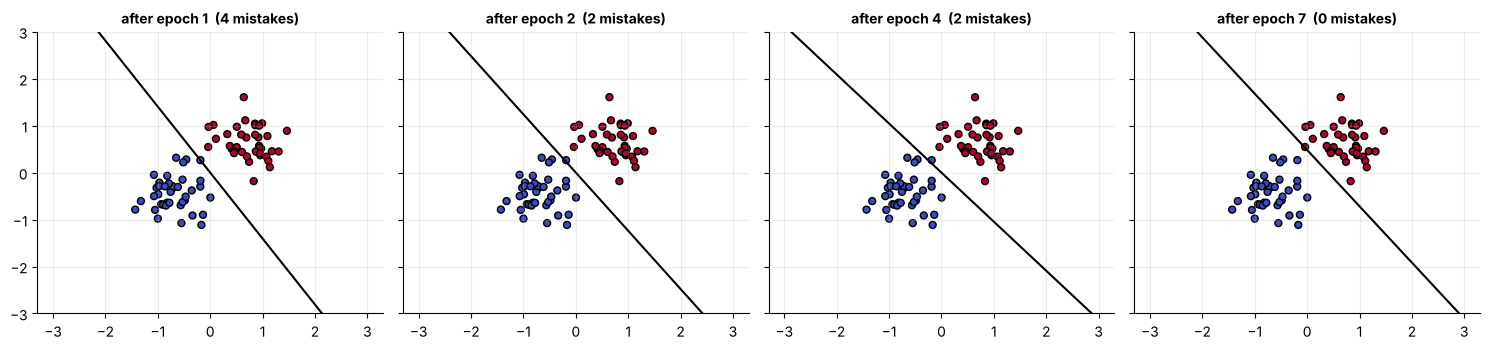

In [7]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=80, centers=[[-0.7, -0.5], [0.8, 0.7]], cluster_std=0.38, random_state=13)
w, b, mistakes, snaps = train_perceptron(X, y, lr=0.2, epochs=15, record=True)
print("mistakes per epoch:", mistakes)

show = sorted({0, 1, 3, len(snaps) - 1})
fig, axes = plt.subplots(1, len(show), figsize=(15, 3.6), sharex=True, sharey=True)
for ax, k in zip(axes, show):
    wk, bk = snaps[k]
    xs = np.linspace(-3, 3, 50)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=25)
    if abs(wk[1]) > 1e-9: ax.plot(xs, -(wk[0] * xs + bk) / wk[1], "k-")
    ax.set_ylim(-3, 3); ax.set_title(f"after epoch {k + 1}  ({mistakes[k]} mistakes)", fontsize=10)
plt.tight_layout(); plt.show()

> 🧪 **Try it yourself**: Re-run with `lr=0.01` and `lr=5`. Does the *final* line change? (Hint: for the perceptron, with zero initial weights, the learning rate only rescales $w$ and $b$ together; the boundary is identical. This is special to the perceptron; in later lessons the learning rate matters enormously!)

---
## 🧱 7. The XOR wall

XOR ("exclusive or") outputs 1 when the inputs **differ**: (0,1)→1, (1,0)→1, but (0,0)→0 and (1,1)→0.
Let's ask our perceptron to learn it…

mistakes per epoch (first 12): [2, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4] ... total epochs run: 100
final predictions: [1 1 0 0]  (target: [0 1 1 0] )


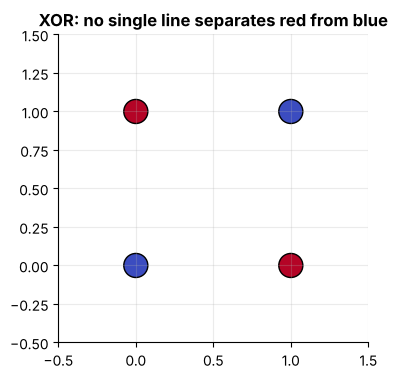

In [8]:
XOR = np.array([0, 1, 1, 0])
w, b, m = train_perceptron(inputs.astype(float), XOR, epochs=100)
print("mistakes per epoch (first 12):", m[:12], "... total epochs run:", len(m))
print("final predictions:", (inputs @ w + b > 0).astype(int), " (target:", XOR, ")")

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(inputs[:, 0], inputs[:, 1], c=XOR, cmap="coolwarm", s=300, edgecolor="k")
ax.set_title("XOR: no single line separates red from blue"); ax.set_xlim(-.5, 1.5); ax.set_ylim(-.5, 1.5)
plt.show()

It **never** gets zero mistakes: it will oscillate forever. And the picture shows why: the red points are on opposite
corners; no straight line can put both reds on one side and both blues on the other. **A single neuron can only draw a single straight cut.**

> 📜 **The first AI winter.** In 1969 Minsky & Papert published *Perceptrons*, proving this limitation. Funding for neural
> networks dried up for over a decade. The fix was known (stack neurons in layers!) but nobody had a good way to *train*
> those layers until **backpropagation** was popularised in 1986. You'll build both in the next lessons.

🤔 **Pause and think.** Looking at the XOR picture: how could *two* lines together carve out the blue region? And how could a *second* layer combine the two lines' answers?

<details><summary>Click to reveal the answer</summary>

Line 1 says "at least one input is on" (OR); line 2 says "not both are on" (NAND). The blue points are where **both** statements are true, so a second neuron computing AND of those two answers solves XOR. *That's a hidden layer.* We do exactly this in Lesson 02.

</details>

---
# 🏋️ Practice problems
Work through these in order. Each problem has **hints** (open them one at a time: struggling a little is how learning happens!) and a **self-check cell** that tells you ✅ or ❌. Full solutions live in `../solutions/`.

*Difficulty:* ⭐ warm-up · ⭐⭐ standard · ⭐⭐⭐ challenge

---
### 🧩 Problem 1.1: The planting neuron  &nbsp; `⭐`

Write `plant_decision(X, w, b)` that takes a batch `X` of shape `(n, 3)` and returns an integer array of 0/1 decisions
(1 if `z > 0`). Use **no loops**: one matrix–vector product.

<details><summary>💡 Hint 1</summary>

`X @ w` gives all weighted sums at once.

</details>

<details><summary>💡 Hint 2</summary>

Compare with `> 0`, then convert booleans with `.astype(int)`.

</details>


In [ ]:
def plant_decision(X, w, b):
    pass   # YOUR CODE HERE

In [ ]:
# ▶ self-check (run after you've written your answer)
X = np.array([[1,1,0],[1,0,0],[1,1,1],[0,1,0]])
out = plant_decision(X, np.array([3.,2.,-2.]), -3.)
dl.check("returns array of shape (4,)", out is not None and np.asarray(out).shape == (4,))
dl.check("decisions are [1, 0, 0, 0]", out is not None and list(out) == [1, 0, 0, 0],
         "(1,1,0): z=2>0 → plant; (1,0,0): z=0 → wait")

---
### 🧩 Problem 1.2: Design NAND and NOR  &nbsp; `⭐⭐`

**NAND** = NOT(AND): outputs 0 only when both inputs are 1. **NOR** = NOT(OR): outputs 1 only when both inputs are 0.
Choose weights and biases (fill the four variables) so the neurons reproduce the truth tables on all four inputs.
*(NAND is famous: every digital circuit can be built from NAND gates alone, so networks of neurons can compute anything a computer can!)*

<details><summary>💡 Hint 1</summary>

Start from AND (`w=(1,1)`, `b=-1.5`) and flip the signs.

</details>

<details><summary>💡 Hint 2</summary>

NAND: negative weights mean 'both on' makes z very negative.

</details>

<details><summary>💡 Hint 3</summary>

NAND: need z>0 for (0,0),(0,1),(1,0) but z≤0 for (1,1). Try `w=(-1,-1)` and solve for `b`.

</details>


In [ ]:
w_nand, b_nand = None, None   # e.g. np.array([?, ?]), ?
w_nor,  b_nor  = None, None

In [ ]:
# ▶ self-check (run after you've written your answer)
inp = np.array([[0,0],[0,1],[1,0],[1,1]])
ok = w_nand is not None and w_nor is not None
dl.check("NAND truth table", ok and list((inp @ np.asarray(w_nand) + b_nand > 0).astype(int)) == [1,1,1,0])
dl.check("NOR truth table",  ok and list((inp @ np.asarray(w_nor)  + b_nor  > 0).astype(int)) == [1,0,0,0])

---
### 🧩 Problem 1.3: Majority vote of three  &nbsp; `⭐⭐`

Three sensors each say 1 ("disease") or 0 ("healthy"). Design a **single neuron** that outputs 1 when **at least two** of the three
sensors say 1. Fill in `w_maj` (length 3) and `b_maj`.

<details><summary>💡 Hint 1</summary>

By symmetry all three weights should be equal.

</details>

<details><summary>💡 Hint 2</summary>

With weights of 1, `z = (number of ones) + b`. You need z>0 when the count is ≥2 but ≤0 when it is ≤1.

</details>


In [ ]:
w_maj, b_maj = None, None

In [ ]:
# ▶ self-check (run after you've written your answer)
import itertools
combos = np.array(list(itertools.product([0, 1], repeat=3)))
want = (combos.sum(1) >= 2).astype(int)
got = (combos @ np.asarray(w_maj) + b_maj > 0).astype(int) if w_maj is not None else None
dl.check("majority gate correct on all 8 inputs", got is not None and np.array_equal(got, want))

---
### 🧩 Problem 1.4: Train your own perceptron  &nbsp; `⭐⭐`

Re-implement `train_perceptron(X, y, lr, epochs)` **without peeking** at the lesson. It must return `(w, b)`.
Stop early if an entire pass has zero mistakes. It should learn AND, OR and a linearly separable blob dataset perfectly.

<details><summary>💡 Hint 1</summary>

Initialise `w = np.zeros(n_features)` and `b = 0.0`.

</details>

<details><summary>💡 Hint 2</summary>

Loop epochs → loop examples → predict → `error = y - y_hat` → update both `w` and `b`.

</details>

<details><summary>💡 Hint 3</summary>

Remember to update the bias too: `b += lr * error`.

</details>


In [ ]:
def train_perceptron(X, y, lr=1.0, epochs=50):
    pass   # YOUR CODE HERE
    # return w, b

In [ ]:
# ▶ self-check (run after you've written your answer)
from sklearn.datasets import make_blobs
inp = np.array([[0,0],[0,1],[1,0],[1,1]], float)
for name, t in [("AND", [0,0,0,1]), ("OR", [0,1,1,1])]:
    res = train_perceptron(inp, np.array(t))
    ok = res is not None and np.array_equal((inp @ res[0] + res[1] > 0).astype(int), t)
    dl.check(f"learns {name}", ok)
Xb, yb = make_blobs(60, centers=[[-2,-2],[2,2]], cluster_std=0.7, random_state=0)
res = train_perceptron(Xb, yb)
dl.check("100% accuracy on separable blobs", res is not None and ((Xb @ res[0] + res[1] > 0).astype(int) == yb).all())

---
### 🧩 Problem 1.5: The boundary line (challenge)  &nbsp; `⭐⭐⭐`

For a 2-input neuron the decision boundary is the line $w_1x_1+w_2x_2+b=0$. Write `boundary_line(w, b)` returning
the **slope** and **intercept** of that line in the form $x_2 = \text{slope}\cdot x_1 + \text{intercept}$.
Then write `distance_to_boundary(x, w, b)` giving the **signed perpendicular distance** from point `x` to the line
(positive on the "fires" side). This distance is what *margin*-based methods like SVMs maximise.

<details><summary>💡 Hint 1</summary>

Solve $w_2x_2 = -w_1x_1 - b$ for $x_2$.

</details>

<details><summary>💡 Hint 2</summary>

Signed distance from a point to a line: $(\mathbf{w}\cdot\mathbf{x}+b)/\|\mathbf{w}\|$.

</details>

<details><summary>💡 Hint 3</summary>

`np.linalg.norm(w)` is $\|\mathbf{w}\|$.

</details>


In [ ]:
def boundary_line(w, b):
    pass  # return slope, intercept

def distance_to_boundary(x, w, b):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
w, b = np.array([2., 4.]), -4.
res = boundary_line(w, b)
dl.check("slope = -0.5, intercept = 1", res is not None and np.allclose(res, (-0.5, 1.0)))
d = distance_to_boundary(np.array([0., 0.]), w, b)
dl.check("origin is on the 'off' side, distance −4/√20", d is not None and np.isclose(d, -4 / np.sqrt(20)))
d0 = distance_to_boundary(np.array([0., 1.]), w, b)
dl.check("point on the line has distance 0", d0 is not None and np.isclose(d0, 0))

---
## 🏁 Key takeaways
- ✅ A neuron computes **z = w·x + b** then applies an **activation**: the weights say what matters, the bias says how easily it fires.
- ✅ Geometrically a neuron is a **linear classifier**: one straight line (hyperplane) splitting the space.
- ✅ The **perceptron rule** nudges weights toward examples it got wrong; it converges on any linearly separable data.
- ✅ A single neuron **cannot learn XOR**: the cure is *depth*: stacking neurons into layers.

---
## 🧠 Check your understanding
Try to answer *out loud* before you open the answer. If you can explain it to a friend, you own it.
**Q1.** If you double *all* the weights and the bias of a step-activation neuron, does its decision boundary change?

<details><summary>Answer</summary>

No. `z` doubles, but the *sign* of `z` (which side of zero) is unchanged. Only the ratios between weights and bias determine the line.

</details>

**Q2.** What does a negative bias do?

<details><summary>Answer</summary>

It makes the neuron harder to activate: the weighted sum must exceed |b| before it fires.

</details>

**Q3.** Why is XOR not linearly separable?

<details><summary>Answer</summary>

Its two positive examples are on opposite corners of the square; any line that separates one positive from the negatives also leaves the other positive on the wrong side.

</details>

---
## 📚 Go deeper (optional)
- Rosenblatt (1958): *The Perceptron: A Probabilistic Model for Information Storage and Organization in the Brain*
- Minsky & Papert (1969): *Perceptrons*
- Nielsen, *Neural Networks and Deep Learning*, Chapter 1: perceptrons and sigmoid neurons

---
⬅️ Previous: [00 · Welcome, Setup & Your First Neural Network](00_welcome_and_setup.ipynb) &nbsp;|&nbsp; Next: [02 · Layers, Weights & Activation Functions](02_layers_and_activations.ipynb) ➡️